In [2]:
import sys
from pathlib import Path

notebook_dir = Path.cwd() 
project_root = notebook_dir.parent 

# Thêm thư mục gốc vào đầu danh sách tìm kiếm của Python
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from src.models.naive_bayes import GaussianNB
from src.models.mlp import MLP
from src.preprocessing.preprocess import load_processed_data
from src.evaluation.evaluator import Evaluator
from src.utils.paths import *

#  NB va MLP (co LR roi thi them vo luon)

In [4]:
NB_PARAMS = {"var_smoothing": 0.1} 
MLP_PARAMS = {'hidden_sizes': (1024, 256), 'p_drop': 0.0, 'learning_rate': 0.08, 'momentum': 0.8, 'batch_size': 64}

In [5]:
X_train, y_train, X_val, y_val, _, _ = load_processed_data()
print("X_train", tuple(X_train.shape), "| X_val", tuple(X_val.shape))
print("So mau moi lop (train):", torch.bincount(y_train).tolist())
print("Working directory:", Path.cwd())
print("Processed folder:", PROCESSED_PATH.resolve())

X_train (50000, 784) | X_val (10000, 784)
So mau moi lop (train): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]
Working directory: /home/tim/General Code/Pattern_Recognition/WriteRHand/notebooks
Processed folder: /home/tim/General Code/Pattern_Recognition/WriteRHand/data/processed


Chỉ đánh giá trên tập val để lấy confusion matrix của những ảnh sai, nhằm mục đích đo diversity để biết model hợp kết hợp với nhau cho ensemble

In [6]:
models = {"GaussianNB": GaussianNB(**NB_PARAMS), "MLP": MLP(**MLP_PARAMS)}
evaluators = {}

for name, model in models.items():
    ev = Evaluator(name, model)
    ev.fit(X_train, y_train)
    ev.eval_all(X_train, y_train, X_val, y_val, None, None)
    ev.save()
    evaluators[name] = ev
    print(f"{name}: huấn luyện {ev.results['train_time_sec']:.1f}s")

GaussianNB: huấn luyện 0.8s
MLP: huấn luyện 82.3s


## Bang benchmark

In [9]:
def scalar_metrics(d):
    """Giữ các chỉ số là số, bỏ confusion matrix."""
    return {k: float(v) for k, v in d.items() if k not in ["confusion_matrix", "report"]}

rows = []
for name, ev in evaluators.items():
    for split, m in ev.results["splits"].items():
        rows.append({"model": name, "split": split, **scalar_metrics(m)})
df = pd.DataFrame(rows)
print("Các cột chỉ số:", df.columns.tolist())

# Accuracy theo tập và độ chênh train - val (dấu hiệu overfit)
acc = df.pivot(index="model", columns="split", values="accuracy")[["train", "val"]]
acc["train_minus_val"] = acc["train"] - acc["val"]
display(acc.round(4))

# Mọi chỉ số trên val, kèm thời gian
test = df[df["split"] == "val"].set_index("model").drop(columns="split")
test["train_time_sec"] = [evaluators[m].results["train_time_sec"] for m in test.index]
display(test.round(4))

Các cột chỉ số: ['model', 'split', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'predict_time_sec']


split,train,val,train_minus_val
model,,,
GaussianNB,0.8018,0.7938,0.0080
MLP,0.9988,0.9817,0.0171


,accuracy,precision_macro,recall_macro,f1_macro,predict_time_sec,train_time_sec
model,,,,,,
GaussianNB,0.7938,0.8116,0.7896,0.7924,0.2991,0.8348
MLP,0.9817,0.9816,0.9815,0.9815,0.3152,82.3246


## Confusion matrix

GaussianNB - cặp nhầm nhiều nhất:
   thật 4 -> đoán 9: 259 mẫu
   thật 7 -> đoán 9: 116 mẫu
   thật 8 -> đoán 1: 103 mẫu
MLP - cặp nhầm nhiều nhất:
   thật 9 -> đoán 4: 14 mẫu
   thật 3 -> đoán 2: 10 mẫu
   thật 5 -> đoán 6: 7 mẫu


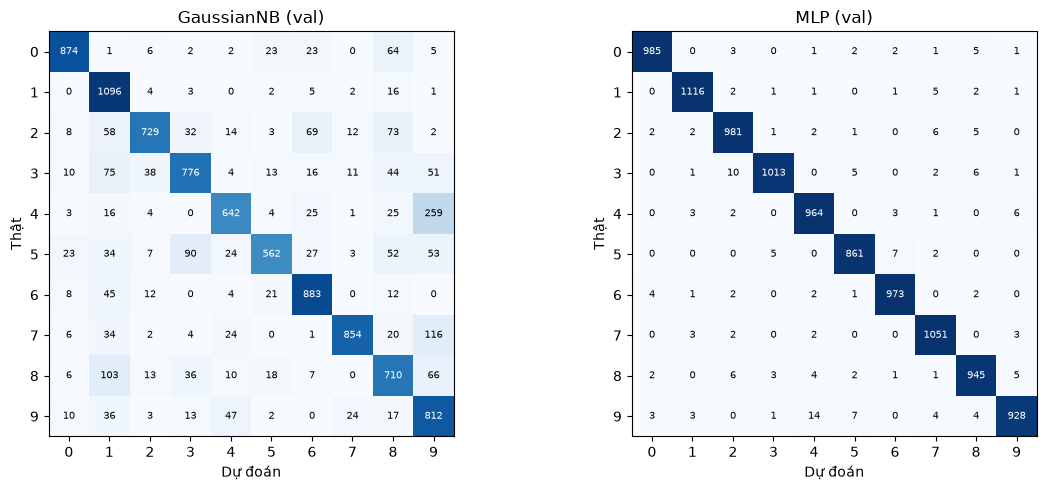

In [11]:
fig, axes = plt.subplots(1, len(evaluators), figsize=(6 * len(evaluators), 5))
for ax, (name, ev) in zip(axes, evaluators.items()):
    m = ev.results["splits"]["val"]
    cm = np.array(next(v for v in m.values() if np.ndim(v) == 2), dtype=float)
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(int(cm[i, j])), ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
    ax.set_title(f"{name} (val)")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thật")
    ax.set_xticks(range(cm.shape[1])); ax.set_yticks(range(cm.shape[0]))

    off = cm.copy(); np.fill_diagonal(off, 0)
    print(f"{name} - cặp nhầm nhiều nhất:")
    for flat in np.argsort(off, axis=None)[::-1][:3]:
        i, j = divmod(flat, cm.shape[1])
        print(f"   thật {i} -> đoán {j}: {int(off[i, j])} mẫu")
plt.tight_layout(); plt.show()